# Nearest Neighbor Search

**Seong Cho** · ACME Volume 2, Lab 3

**Lab objective:** implement a k-d tree, a variation of the binary search tree, use it to solve the nearest neighbor search problem efficiently, then apply SciPy's k-d tree object to a handwriting recognition algorithm.

<sub>Lab specification from the *Volume 2* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

The k-d tree classes build on `BSTNode` and `BST` from my Binary Search Tree module, [`trees.py`](trees.py), from the previous (Trees) lab, kept next to this notebook. The spec's `sys.path.insert(1, "../Trees")` line is kept as written; Python finds `trees.py` in the notebook's own folder. Importing the module runs no code, but when Python 3.12 or later first compiles it, it issues a `SyntaxWarning` for the `\ ` in the ASCII-art tree diagrams of two docstrings, so the setup cell silences that warning.

In [1]:
import warnings
import numpy as np
import scipy as sp
from numpy import linalg as la
import sys
sys.path.insert(1, "../Trees")
warnings.filterwarnings("ignore", category=SyntaxWarning)
from trees import BSTNode
from trees import BST
from scipy.spatial import KDTree

import inspect
from matplotlib import pyplot as plt
from sklearn import neighbors

In [2]:
print(inspect.getsource(BSTNode))

class BSTNode:
    """A Node class for Binary Search Trees. Contains some data, a
    reference to the parent node, and references to two child nodes.
    """
    def __init__(self, data):
        """Construct a new node and set the data attribute. The other
        attributes will be set when the node is added to a tree.
        """
        self.value = data
        self.prev = None        # A reference to this node's parent node.
        self.left = None        # self.left.value < self.value
        self.right = None       # self.value < self.right.value



## The Nearest Neighbor Problem

Suppose you move into a new city with several post offices and wish to know which one is closest to your home. This is the *nearest neighbor search problem*, which arises in computer vision, pattern recognition, internet marketing, and data compression. In general, let $X$ be a collection of data, called a *training set*, and let $\mathbf{y}$ be any point (the *target point*) in the same space. The problem is to find the point in $X$ closest to $\mathbf{y}$. In the post office problem, $X$ could be the addresses or latitude and longitude of each post office, and $\mathbf{y}$ the data for your new home.

## Problem 1: The Euclidean metric

> **Problem 1.** Roughly speaking, a function that measures the distance between two points in a set is called a *metric*. The Euclidean metric measures the distance between two points in $\mathbb{R}^n$ with the familiar distance formula:
>
> $$d(\mathbf{x}, \mathbf{y}) = \sqrt{\sum_{i=1}^n (x_i - y_i)^2} = \|\mathbf{x} - \mathbf{y}\|_2$$
>
> Write a function that accepts two 1-dimensional NumPy arrays and returns the Euclidean distance between them. Raise a `ValueError` if the arrays don't have the same number of entries.
>
> (Hint: NumPy already has some functions to help do this quickly.)

(Metrics and metric spaces are examined in detail in Chapter 5 of Volume I.)

In [3]:
def metric(x, y):
    """Return the Euclidean distance between the 1-D arrays 'x' and 'y'.

    Raises:
        ValueError: if 'x' and 'y' have different lengths.

    Example:
        >>> metric([1,2],[2,2])
        1.0
        >>> metric([1,2,1],[2,2])
        ValueError: Incompatible dimensions.
    """
    if len(x) != len(y):
        raise ValueError("Incompatible dimensions")
    x = np.array(x)
    y = np.array(y)
    return la.norm(y - x)

In [4]:
print(metric([1,2],[2,2]), metric(np.array([0,0,0]), np.array([1,2,2])))
try:
    metric([1,2,1],[2,2])
except ValueError as e:
    print("ValueError:", e)

rng = np.random.default_rng(1)
x, y = rng.random(10), rng.random(10)
assert np.isclose(metric(x, y), sp.spatial.distance.euclidean(x, y))

1.0 3.0
ValueError: Incompatible dimensions


## Exhaustive Search

One way to find the closest post office is to drive from home to each one, measure the mileage, and choose the closest. This *exhaustive search* measures the distance from $\mathbf{y}$ to each point in $X$ and picks the smallest. It is inefficient, and only feasible for relatively small training sets.

## Problem 2: Exhaustive search

> **Problem 2.** Write a function that solves the nearest neighbor search problem by exhaustively checking all of the distances between a given point and each point in a data set. The function should take in a set of data points (as an $m \times k$ NumPy array, where each row represents one of the $m$ points in the data set) and a single target point (as a 1-dimensional NumPy array with $k$ entries). Return the point in the training set that is closest to the target point and its distance from the target.
>
> The complexity of this algorithm is $O(mk)$, where $k$ is the number of dimensions and $m$ is the number of data points.

In [5]:
def exhaustive_search(data_set, target):
    """Solve the nearest neighbor search problem exhaustively. Check the distances between 'target' and each point in 'data_set'. Use the Euclidean metric to calculate distances.

    Parameters:
        data_set ((m,k) ndarray): An array of m k-dimensional points.
        target ((k,) ndarray): A k-dimensional point to compare to 'dataset'.

    Returns:
        ((k,) ndarray) the member of 'data_set' that is nearest to 'target'.
        (float) The distance from the nearest neighbor to 'target'.
    """
    nearest_dist = metric(data_set[0], target)
    nearest_pt = data_set[0]
    for X in data_set:
        dist = metric(X, target)
        if nearest_dist > dist:
            nearest_dist = dist
            nearest_pt = X
    return nearest_pt, nearest_dist

Checked against a vectorized computation of all the distances at once:

In [6]:
rng = np.random.default_rng(2)
data, target = rng.random((1000, 4)), rng.random(4)
pt, dist = exhaustive_search(data, target)
print(pt, dist)
dists = np.linalg.norm(data - target, axis=1)
assert np.allclose(pt, data[np.argmin(dists)]) and np.isclose(dist, dists.min())

[0.88343617 0.3909442  0.80063478 0.06814342] 0.1746387656999542


## K-D Trees

A *k-d tree* is a binary search tree for data with more than one dimension. A binary search tree excludes regions of the number line from a search (going left when the value is less than the current node and right when it is larger), so far fewer points are searched; a k-d tree does the same on regions of $\mathbb{R}^k$. As long as the data meets certain dimensionality requirements, similar efficiency gains are possible.

The root has depth 0. At the $i$th level, the nodes to the left of a parent have a strictly lower value in the $i$th dimension, and the nodes to the right have a greater or equal value; the next level does the same for the next dimension. For data in $\mathbb{R}^3$, the root partitions the data by the first dimension, its children by the second, and its grandchildren by the third.

In the spec's Figure 3.1, a tree in $\mathbb{R}^2$ is loaded with $(5,5)$, $(8,4)$, $(3,2)$, $(7,7)$, and $(2,6)$, in that order, and then $(9,2)$ is inserted. Starting at the root, the $x$-coordinate of $(9,2)$ is greater than that of $(5,5)$, so move into the right subtree, excluding all points with $x < 5$. Next, the $y$-coordinate of $(9,2)$ is less than that of $(8,4)$, so move left, excluding all points with $y > 4$. Since $(8,4)$ has no left child, $(9,2)$ becomes its left child. Figure 3.2 then inserts $(4,7)$: $4 < 5$, so go to the root's left child $(3,2)$; $7 > 2$, so go to its right child $(2,6)$; $4 > 2$ and $(2,6)$ has no right child, so $(4,7)$ becomes the right child of $(2,6)$.

A `KDTNode` is like a `BSTNode` with one more attribute, `axis`, the dimension of $\mathbb{R}^k$ used to compare points at that node.

## Problem 3: The `KDTNode` class

> **Problem 3.** Import the `BSTNode` class from the previous lab using the following code:
>
> ```python
> import sys
> sys.path.insert(1, "../Trees")
> from trees import BSTNode
> ```
>
> Write a `KDTNode` class that inherits from `BSTNode`. Modify the constructor so that a `KDTNode` can only hold a NumPy array (of type `np.ndarray`). If any other data type is given, raise a `TypeError`. Create an `axis` attribute (set it to `None` or `0` for now).

In [7]:
class KDTNode(BSTNode):
    def __init__(self, data):
        if type(data) != np.ndarray:
            raise TypeError("Input must be numpy.ndarray")
        BSTNode.__init__(self, data)
        self.axis = None

In [8]:
node = KDTNode(np.array([3, 1, 4]))
print(node.value, node.axis, node.left, node.right, node.prev)
for bad in [[3, 1, 4], (3, 1, 4), 5, "314"]:
    try:
        KDTNode(bad)
    except TypeError as e:
        print(f"{bad!r:>10}: TypeError: {e}")

[3 1 4] None None None None
 [3, 1, 4]: TypeError: Input must be numpy.ndarray
 (3, 1, 4): TypeError: Input must be numpy.ndarray
         5: TypeError: Input must be numpy.ndarray
     '314': TypeError: Input must be numpy.ndarray


## The `KDT` Class

The major difference between a k-d tree and a binary search tree is how data is compared at each depth. Each comparison in `find()`'s recursive `_step()` uses the `axis` attribute of the current node, so as long as every node has the correct axis, the correct comparisons are made on the way down. The nearest neighbor problem does not need `find()`, but the spec provides it as an instructive example; it is the first method of the `KDT` class below.

In the spec's Figure 3.3, a tree in $\mathbb{R}^3$ has root $(3,1,4)$. To find $(7,1,6)$: $7 > 3$, so move to the right subtree $(4,3,4)$; $1 < 3$ in the second coordinate, so move to its left subtree; and so on, back to the first dimension after the third, until $(7,1,6)$ is found.

## Problem 4: The `KDT` class

> **Problem 4.** Finish implementing the `KDT` class.
> 1. Override the `insert()` method. To insert a new node, find the node that should be the parent of the new node by recursively descending through the tree as in the `find()` method (see Figure 3.2 for a geometric example). Do not allow duplicate nodes in the tree. Note that the `k` attribute will be initialized when a k-d tree object is instantiated. The `axis` attribute of the new node will be one more than that `axis` of the parent node. If the last dimension of the data has been reached, start `axis` over at 0.
> 2. To prevent a user from altering the tree, disable the `remove()` method. Raise a `NotImplementedError` if the method is called, and allow it to receive any number of arguments. (Disabling the `remove()` method ensures that the k-d tree remains the same after it is created. The same k-d tree is used multiple times with different target points to solve the nearest neighbor search problem.)

In [9]:
class KDT(BST):
    """A k-dimensional binary search tree object. Used to solve the nearest neighbor problem efficiently.

    Attributes:
        root (KDTNode): The root node of the tree. Like all other nodes in the
            tree, the root houses data as a NumPy array.
        k (int): The dimension of the tree (the 'k' of the k-d tree).
    """

    def find(self, data):
        """Return the node containing 'data'. If there is no such node in the tree, or if the tree is empty, raise a ValueError.
        """

        # Define a recursive function to traverse the tree.
        def _step(current):
            """Recursively step through the tree until the node containing 'data' is found. If there is no such node, raise a Value Error.
            """
            if current is None:                     # Base case 1: dead end.
                raise ValueError(str(data) + " is not in the tree")
            elif np.allclose(data, current.value):
                return current                      # Base case 2: data found!
            elif data[current.axis] < current.value[current.axis]:
                return _step(current.left)          # Recursively search left.
            else:
                return _step(current.right)         # Recursively search right.

        # Start the recursion on the root of the tree.
        return _step(self.root)

    def insert(self, data):
        """Insert a new node containing 'data' at the appropriate location.
        Return the new node. This method should be similar to BST.insert().
        """
        def _step(node, data):
            if np.allclose(node.value, data):
                raise ValueError(str(data) + " already exists.")
            elif data[node.axis] < node.value[node.axis]:
                if node.left == None:
                    new_node = KDTNode(data)
                    if node.axis == len(node.value) - 1:
                        new_node.axis = 0
                    else:
                        new_node.axis = node.axis + 1
                    node.left = new_node
                    node.left.prev = node
                else:
                    _step(node.left, data)
            else:
                if node.right == None:
                    new_node = KDTNode(data)
                    if node.axis == len(node.value) - 1:
                        new_node.axis = 0
                    else:
                        new_node.axis = node.axis + 1
                    node.right = new_node
                    node.right.prev = node
                else:
                    _step(node.right, data)

        if self.root == None:
            new_node = KDTNode(data)
            new_node.axis = 0
            self.root = new_node
        else:
            _step(self.root, data)

    def remove(*args, **kwargs):
        raise NotImplementedError("remove() has been disabled for this class.")

The trees of Figures 3.1 and 3.2, printed level by level with `BST.__str__()` from `trees.py`: $(9,2)$ is the left child of $(8,4)$, and $(4,7)$ is the right child of $(2,6)$.

In [10]:
tree = KDT()
for p in [(5,5), (8,4), (3,2), (7,7), (2,6), (9,2), (4,7)]:
    tree.insert(np.array(p))
print(tree)

assert np.array_equal(tree.root.right.left.value, [9,2])
assert np.array_equal(tree.root.left.right.right.value, [4,7])
assert tree.find(np.array([9,2])).prev is tree.root.right
assert [tree.root.axis, tree.root.right.axis, tree.root.right.left.axis] == [0, 1, 0]

for bad_call in [lambda: tree.insert(np.array([7,7])),
                 lambda: tree.find(np.array([1,1])),
                 lambda: tree.remove(np.array([5,5])),
                 lambda: tree.remove()]:
    try:
        bad_call()
    except (ValueError, NotImplementedError) as e:
        print(f"{type(e).__name__}: {e}")

[array([5, 5])]
[array([3, 2]), array([8, 4])]
[array([2, 6]), array([9, 2]), array([7, 7])]
[array([4, 7])]

ValueError: [7 7] already exists.
ValueError: [1 1] is not in the tree
NotImplementedError: remove() has been disabled for this class.
NotImplementedError: remove() has been disabled for this class.


The partition this tree makes of the plane, as in the spec's Figure 3.2: each node splits its region with a vertical line (axis 0) or a horizontal line (axis 1).

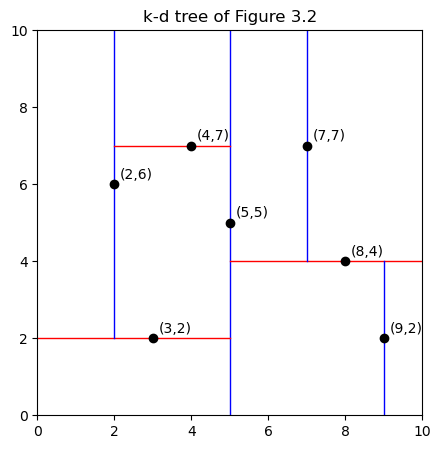

In [11]:
def draw_partition(node, xlim, ylim, ax):
    if node is None:
        return
    x, y = node.value
    if node.axis == 0:
        ax.plot([x, x], ylim, 'b-', lw=1)
        draw_partition(node.left, (xlim[0], x), ylim, ax)
        draw_partition(node.right, (x, xlim[1]), ylim, ax)
    else:
        ax.plot(xlim, [y, y], 'r-', lw=1)
        draw_partition(node.left, xlim, (ylim[0], y), ax)
        draw_partition(node.right, xlim, (y, ylim[1]), ax)
    ax.plot(x, y, 'ko')
    ax.annotate(f"({x},{y})", (x, y), textcoords="offset points", xytext=(4, 4))

fig, ax = plt.subplots(figsize=(5, 5))
draw_partition(tree.root, (0, 10), (0, 10), ax)
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_aspect("equal")
ax.set_title("k-d tree of Figure 3.2")
plt.show()

Figure 3.3's tree in $\mathbb{R}^3$, inserted level by level, and the search path to $(7,1,6)$ through `find()`:

In [12]:
tree3 = KDT()
for p in [(3,1,4), (2,3,7), (4,3,4), (2,1,3), (2,4,5), (6,1,4),
          (1,4,4), (0,5,7), (5,2,5), (4,0,6), (7,1,6)]:
    tree3.insert(np.array(p))
print(tree3)

node = tree3.find(np.array([7,1,6]))
path = []
while node is not None:
    path.append((tuple(int(v) for v in node.value), node.axis))
    node = node.prev
print("path (node, axis):", path[::-1])
assert [p for p, a in path[::-1]] == [(3,1,4), (4,3,4), (6,1,4), (5,2,5), (7,1,6)]

[array([3, 1, 4])]
[array([2, 3, 7]), array([4, 3, 4])]
[array([2, 1, 3]), array([2, 4, 5]), array([6, 1, 4])]
[array([1, 4, 4]), array([0, 5, 7]), array([5, 2, 5])]
[array([4, 0, 6]), array([7, 1, 6])]

path (node, axis): [((3, 1, 4), 0), ((4, 3, 4), 1), ((6, 1, 4), 2), ((5, 2, 5), 0), ((7, 1, 6), 1)]


## Nearest Neighbor Search with a K-D Tree

A procedure like `find()` or `insert()` does not immediately give the nearest neighbor. Keep track of the target point, the current search node, the current best point, and the current minimum distance. Start at the root, with the root as both the search node and best point and the distance from the root to the target as the minimum distance, and proceed recursively as in `find()`, updating these as nearer neighbors are found.

Reaching the bottom of the tree gives a "close" neighbor, but not necessarily the closest. To make sure, draw a hypersphere with a radius of the current minimum distance around the candidate: if it does not intersect any of the hyperplanes that split the k-d tree, the candidate is indeed the closest point. In the spec's Figure 3.5 the target is $(8, 4.5)$ in the tree of Figure 3.2: the root is about 3.04 away; the right child $(8,4)$ is only 0.5 away, so it becomes the candidate. $(8,4)$ is not a leaf, but its child $(7,7)$ is much farther away, and the circle of radius 0.5 around $(8, 4.5)$ does not cross any other splitting line, so the search stops and concludes (correctly) that $(8,4)$ is the nearest neighbor.

The hypersphere is not easy to draw, but there is an equivalent check: before deciding to descend in one direction, add the minimum distance to the $i$th entry of the target, where $i$ is the axis of the candidate. If this sum is greater than the $i$th entry of the current search node, the hypersphere would necessarily intersect one of the hyperplanes drawn by the tree (why?).

```text
Algorithm 3.1  k-d tree nearest neighbor search
1:  Given a set of data and a target, build a k-d tree out of the data set.
2:  procedure Search(current, neighbor, dist)
3:      if current is None then                              ▷ Base case.
4:          return neighbor, dist
5:      index ← current.axis
6:      if metric(current, target) < dist then
7:          neighbor ← current                              ▷ Update the best estimate.
8:          dist ← metric(current, target)
9:      if target[index] < current.value[index] then         ▷ Recurse left.
10:         neighbor, dist ← Search(current.left, neighbor, dist)
11:         if target[index] + dist ≥ current.value[index] then
12:             neighbor, dist ← Search(current.right, neighbor, dist)
13:     else                                                 ▷ Recurse right.
14:         neighbor, dist ← Search(current.right, neighbor, dist)
15:         if target[index] − dist ≤ current.value[index] then
16:             neighbor, dist ← Search(current.left, neighbor, dist)
17:     return neighbor, dist
18: Start Search() at the root of the tree.
```

## Problem 5: Nearest neighbor search with `KDT`

> **Problem 5.** Use Algorithm 3.1 to write a function that solves the nearest neighbor search problem by searching through your `KDT` object. The function should take in a NumPy array of data and a NumPy array representing the target point. Return the nearest neighbor in the data set and the distance from the nearest neighbor to the target point, as in Problem 2 (be sure to return a NumPy array for the neighbor).
>
> To test your function, use SciPy's built-in `KDTree` object. This structure behaves like the `KDT` class, but its operations are heavily optimized. To solve the nearest neighbor problem, initialize the tree with data, then "query" the tree with the target point. The `query()` method returns a tuple of the minimum distance and the index of the nearest neighbor in the data.
>
> ```python
> >>> from scipy.spatial import KDTree
>
> # Initialize the tree with data (in this example, use random data).
> >>> data = np.random.random((100,5))
> >>> target = np.random.random(5)
> >>> tree = KDTree(data)
>
> # Query the tree and print the minimum distance.
> >>> min_distance, index = tree.query(target)
> >>> print(min_distance)
> 0.309671532426
>
> # Print the nearest neighbor by indexing into the tree's data.
> >>> print(tree.data[index])
> [ 0.68001084  0.02021068  0.70421171  0.57488834  0.50492779]
> ```

In [13]:
def nearest_neighbor(data_set, target):
    """Use your KDT class to solve the nearest neighbor problem.

    Parameters:
        data_set ((m,k) ndarray): An array of m k-dimensional points.
        target ((k,) ndarray): A k-dimensional point to compare to 'dataset'.

    Returns:
        The point in the tree that is nearest to 'target' ((k,) ndarray).
        The distance from the nearest neighbor to 'target' (float).
    """
    k = KDT()
    for n in data_set:
        k.insert(n)

    def KDTsearch(current, neighbor, distance):
        """The actual nearest neighbor search algorithm.

        Parameters:
            current (KDTNode): the node to examine.
            neighbor (KDTNode): the current nearest neighbor.
            distance (float): the current minimum distance.

        Returns:
            (ndarray): The new nearest neighbor in the tree.
            (float): The new minimum distance.
        """
        if current == None:
            return neighbor, distance
        if metric(current.value, target) < distance:
            neighbor = current
            distance = metric(current.value, target)
        if target[current.axis] < current.value[current.axis]:
            neighbor, distance = KDTsearch(current.left, neighbor, distance)
            if target[current.axis] + distance >= current.value[current.axis]:
                neighbor, distance = KDTsearch(current.right, neighbor, distance)
        else:
            neighbor, distance = KDTsearch(current.right, neighbor, distance)
            if target[current.axis] - distance <= current.value[current.axis]:
                neighbor, distance = KDTsearch(current.left, neighbor, distance)
        return neighbor, distance

    n,d = KDTsearch(k.root, k.root, metric(k.root.value, target))
    return n.value, d

Figure 3.5's example, then the spec's SciPy `KDTree` session (seeded, so the numbers differ from the spec's), then random data sets in 2 to 7 dimensions checked against both `KDTree.query()` and `exhaustive_search()`.

In [14]:
fig_points = np.array([(5,5), (8,4), (3,2), (7,7), (2,6), (9,2), (4,7)])
print(nearest_neighbor(fig_points, np.array([8, 4.5])))
print("root distance:", metric(fig_points[0], np.array([8, 4.5])))

np.random.seed(3)
# Initialize the tree with data (in this example, use random data).
data = np.random.random((100,5))
target = np.random.random(5)
tree = KDTree(data)
# Query the tree and print the minimum distance.
min_distance, index = tree.query(target)
print(min_distance)
# Print the nearest neighbor by indexing into the tree's data.
print(tree.data[index])
print(nearest_neighbor(data, target))

(array([8, 4]), np.float64(0.5))
root distance: 3.0413812651491097
0.3675156106163294
[0.20937335 0.73070812 0.65112277 0.4789783  0.27478051]
(array([0.20937335, 0.73070812, 0.65112277, 0.4789783 , 0.27478051]), np.float64(0.3675156106163294))


In [15]:
rng = np.random.default_rng(5)
for trial in range(30):
    m, k = int(rng.integers(50, 2000)), int(rng.integers(2, 8))
    data, target = rng.random((m, k)), rng.random(k)
    point, dist = nearest_neighbor(data, target)
    min_distance, index = KDTree(data).query(target)
    assert isinstance(point, np.ndarray)
    assert np.allclose(point, data[index]) and np.isclose(dist, min_distance)
    assert np.isclose(exhaustive_search(data, target)[1], min_distance)
print("All checks passed.")

All checks passed.


## k-Nearest Neighbors

A more general problem is to find the $k$ nearest neighbors of a point (using some metric). The *k-nearest neighbors algorithm* is a machine learning model: a training set of data points comes with *labels*, or classifications, and the model learns to classify new, unlabelled data. For example, data on the incomes and debt levels of $n$ individuals could come with labels saying whether each has filed for bankruptcy, and the goal would be to predict whether a new individual will go bankrupt.

**Classification.** The $k$ nearest neighbors of a new point each "vote" with their label, and the label with the most votes is given to the new point. In the spec's Figure 3.6, a new point's three nearest neighbors are two of type A and one of type B, so it is classified as type A. In the bankruptcy example, if 8 of the 10 nearest neighbors of a new individual went bankrupt, the algorithm predicts that they will too; if 7 had not filed for bankruptcy, it predicts a low risk.

**Handwriting recognition.** A computer image may be thought of as a vector in $\mathbb{R}^n$, where $n$ is the number of pixels and the entries represent how bright each pixel is. If two people write the same number, the vectors for scanned images of them are expected to be close in the Euclidean metric, so the label of a new scanned image can be confidently inferred from a labelled training set.

## Problem 6: A k-nearest neighbors classifier

> **Problem 6.** Write a class that performs the k-nearest neighbors algorithm. The constructor should accept a NumPy array of data (the training set) and a NumPy array of corresponding labels for that data. Use SciPy's `KDTree` class to build a k-d tree from the training set in the constructor.
>
> Write a method for this class that accepts a NumPy array of new data points and an integer $k$. Use the k-nearest neighbors algorithm to predict the label of the new data points. Return a NumPy array of the predicted labels. In the case of ties between labels, choose the label with the smaller identifier (hint: try `scipy.stats.mode()`).
>
> To test your classifier, use the data file `PostalData.npz`. This is a collection of labeled handwritten digits that the United States Postal Service has made available to the public. This data set may be loaded by using the following command:
>
> ```python
> points, testpoints, labels, testlabels = np.load('PostalData.npz').items()
> ```
>
> The first entry of each array is a name, so `points[1]` and `labels[1]` are the actual points and labels to use. Each point is an image that is represented by a flattened $28 \times 28$ matrix of pixels (so each image is a NumPy array of length 784). The corresponding label indicates the number written and is represented by an integer.
>
> Use `labels[1]` and `points[1]` to initialize the classifier. Use `testpoints[1]` for predicting output classes. Choose a random data point from `testpoints[1]`. Plot this point with the following code:
>
> ```python
> import matplotlib.pyplot as plt
> plt.imshow(img.reshape((28,28)), cmap="gray")
> plt.show()
> ```
>
> where `img` is the random data point (a NumPy array of length 784). Your plot should look similar to Figure 3.7.
>
> Use your classifier to predict the label of this data point. Does the output match the number you plotted? Compare the output of your classifier to the corresponding label in `testlabels[1]`. They should be the same.

A similar classification process is used by the United States Postal Service to automatically determine the zip code written or printed on a letter. (The spec's Figure 3.7 shows the number 6 taken from the data set.)

In [16]:
class KNeighborsClassifier(object):
    """A k-nearest neighbors classifier object. Uses SciPy's KDTree to solve
    the nearest neighbor problem efficiently.
    """

    def __init__(self, data, labels):
        """Initialize the training set and labels. Construct the KDTree from
        the training data.

        Parameters:
            data (ndarray): Training data.
            labels (ndarray): Corresponding labels for the training data.
        """
        self.tree = KDTree(data)
        self.data = data
        self.labels = labels

    def predict(self, testpoints, k):
        """Predict the label of a new data point by finding the k-nearest
        neighbors.

        Parameters:
            testpoints (ndarray): New data point(s) to label.
            k (int): Number of neighbors to find.
        """
        def classify(neighbors):
            l = []
            # Changed: np.atleast_1d(). KDTree.query() returns a single index,
            # not an array, when k=1, and looping over it raised a TypeError.
            for i in np.atleast_1d(neighbors):
                l.append(self.labels[i])
            # Changed: keepdims=True. Since SciPy 1.11, stats.mode() returns a
            # scalar mode for 1-D input, so the [0][0] indexing raised an IndexError.
            return sp.stats.mode(l, keepdims=True)[0][0]

        labels = []
        for p in testpoints:
            distances, neighbors = self.tree.query(p, k=k)
            labels.append(classify(neighbors))
        return labels

The tie rule on a small example: with $k = 2$, the two nearest neighbors of $0.4$ are labelled 7 and 4, so the vote is tied and the smaller label, 4, wins. With $k = 3$ the third neighbor breaks the tie.

In [17]:
toy = KNeighborsClassifier(np.array([[0.], [1.], [1.5], [10.]]), np.array([7, 4, 7, 0]))
for k in [1, 2, 3]:
    print(f"k = {k}:", np.array(toy.predict(np.array([[0.4]]), k)))
assert toy.predict(np.array([[0.4]]), 2)[0] == 4 and toy.predict(np.array([[0.4]]), 3)[0] == 7

k = 1: [7]
k = 2: [4]
k = 3: [7]


`PostalData.npz` is no longer published. Its official replacement, `mnist_subset.npz` (next to this notebook), stands in for it: 3,000 training and 500 test images of handwritten digits, each a flattened $28 \times 28$ image of length 784, stored under the keys `X_train`, `y_train`, `X_test`, and `y_test`. The spec's `np.load('PostalData.npz').items()` loading code and its `points[1]`, `labels[1]` indexing do not apply. The images are stored as `uint8`, so they are converted to floats before any distances are computed.

(3000, 784) (3000,) (500, 784) (500,)
labels: [0 1 2 3 4 5 6 7 8 9]


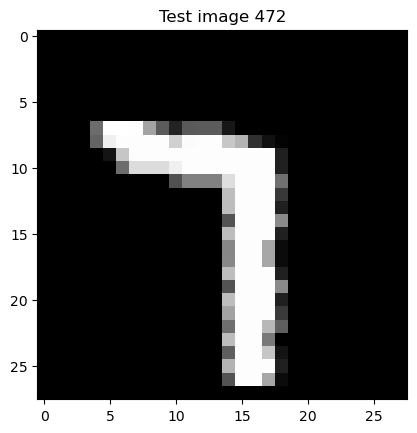

predicted: 7   true label: 7


In [18]:
mnist = np.load('mnist_subset.npz')
points, labels = mnist['X_train'].astype(float), mnist['y_train']
testpoints, testlabels = mnist['X_test'].astype(float), mnist['y_test']
print(points.shape, labels.shape, testpoints.shape, testlabels.shape)
print("labels:", np.unique(labels))

knn = KNeighborsClassifier(points, labels)

rng = np.random.default_rng(7)
i = int(rng.integers(len(testpoints)))
img = testpoints[i]
plt.imshow(img.reshape((28,28)), cmap="gray")
plt.title(f"Test image {i}")
plt.show()

prediction = knn.predict(np.array([img]), 4)[0]
print("predicted:", prediction, "  true label:", testlabels[i])
assert prediction == testlabels[i]

Accuracy on the whole test set for several $k$, and agreement with scikit-learn's `KNeighborsClassifier` (uniform weights, Euclidean metric), which also breaks ties toward the smaller label:

In [19]:
import time
print(" k   accuracy   agrees with sklearn   seconds")
for k in [1, 3, 4, 5, 8]:
    start = time.time()
    predicted = np.array(knn.predict(testpoints, k))
    seconds = time.time() - start
    sk = neighbors.KNeighborsClassifier(n_neighbors=k).fit(points, labels).predict(testpoints)
    print(f"{k:2d}   {np.mean(predicted == testlabels):.3f}      {np.mean(predicted == sk):.3f}"
          f"                 {seconds:.2f}")
    assert np.array_equal(predicted, sk)

 k   accuracy   agrees with sklearn   seconds


 1   0.934      1.000                 0.48


 3   0.910      1.000                 0.59


 4   0.910      1.000                 0.51


 5   0.906      1.000                 0.49


 8   0.898      1.000                 0.48


## Additional Material: sklearn

The `sklearn` package contains powerful tools for the nearest neighbor problem. Its `neighbors` module has a k-nearest neighbors classifier: `n_neighbors` determines how many neighbors to find, `weights` may be `'uniform'` or `'distance'` (the `'distance'` option gives nearer neighbors a more weighted vote), and `p=2` instructs the class to use the Euclidean metric. Its `fit()` method takes arrays of data (the training set) and labels and puts them into a k-d tree, much like the `KDT` class above; `predict()` does a k-nearest neighbor search on the tree and uses the result to label unlabeled points, and `score()` gives the accuracy. More information is at http://scikit-learn.org/stable/modules/neighbors.html.

In [20]:
# Create an instance of a k-nearest neighbors classifier.
nbrs = neighbors.KNeighborsClassifier(n_neighbors=8, weights='distance', p=2)
nbrs.fit(points, labels)
prediction = nbrs.predict(testpoints)
print(prediction[:20])
nbrs.score(testpoints, testlabels)

[4 9 3 9 7 5 1 1 0 5 9 6 4 9 2 1 0 9 5 5]


0.904